# Chapter 22: Edge cases from the field

Runs every repro in `repros/` once (34 entries: hosted models via OpenRouter, the ShopFlow Postgres, local stub servers, Docker Compose), prints the pass/fail table and what each repro measured, and draws the chapter's charts.

Needs: `.env` configured, `shopflow-db` up (Chapter 0 setup), Docker for F5. Cost: about $0.02 per full run on OpenRouter (2026-11 prices).

In [1]:
import json
import sys
from pathlib import Path

import httpx

sys.path.insert(0, str(Path.cwd()))
from llmprod import get_settings

def key_remaining() -> float:
    r = httpx.get("https://openrouter.ai/api/v1/key", timeout=30,
                  headers={"Authorization": f"Bearer {get_settings().llm_api_key}"})
    return r.json()["data"]["limit_remaining"]

before = key_remaining()
print(f"OpenRouter key: ${before:.4f} remaining before the run")

OpenRouter key: $14.6438 remaining before the run


## Run all repros

PASS means the fix held; the second count says how many failures reproduced on this run.

In [2]:
import run_all

results = run_all.main([])

  A1 PASS (4.0 s)


  A2 PASS (not reproduced) (5.6 s)


  A3 PASS (2.2 s)


openai/gpt-6-luna: ['dropped temperature']


anthropic/claude-sonnet-5.5: ['dropped temperature', "reasoning_effort 'none'->'low'"]


  A4 PASS (3.5 s)


... (27 outputs left out)

  I2 PASS (3.8 s)


  J1 PASS (1.8 s)


  J2 PASS (0.0 s)


id  layer             entry                                            kind   status                    s        $
------------------------------------------------------------------------------------------------------------------
A1  API & tokens      finish_reason == "length" truncates JSON         hosted PASS                    4.0  0.00017
A2  API & tokens      Reasoning eats max_tokens: empty but billed      hosted PASS (not reproduced)   5.6  0.00010
A3  API & tokens      message.content is None                          hosted PASS                    2.2  0.00002
A4  API & tokens      Reasoning models reject temperature              hosted PASS                    3.5  0.00009
A5  API & tokens      Unicode and tokenization surprises               hosted PASS                    2.1  0.00022
A6  API & tokens      Context overflow is silent                       hosted PASS                    1.5  0.00095
B1  Structured output json_object returns fenced/prose JSON            hosted PA

## Charts

22-overview.png


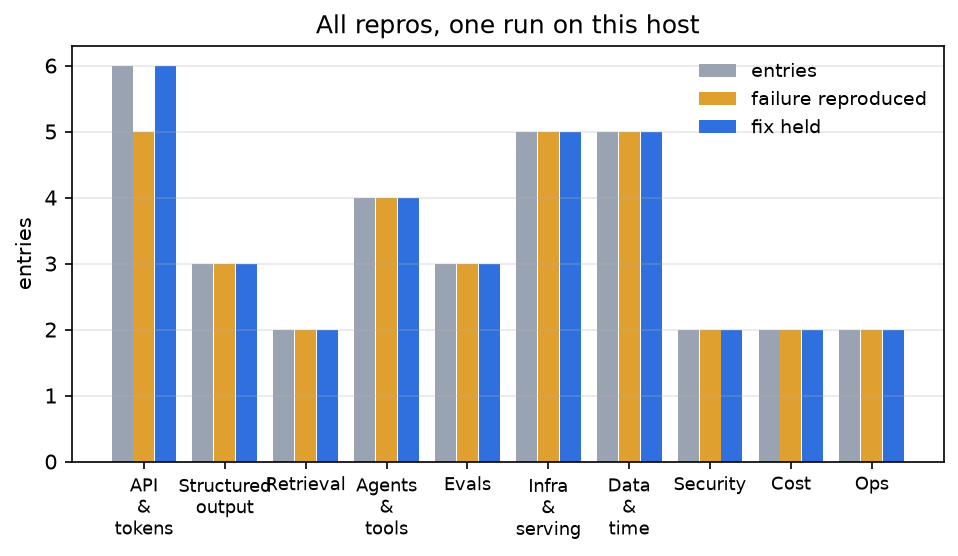

22-agent-runaway.png


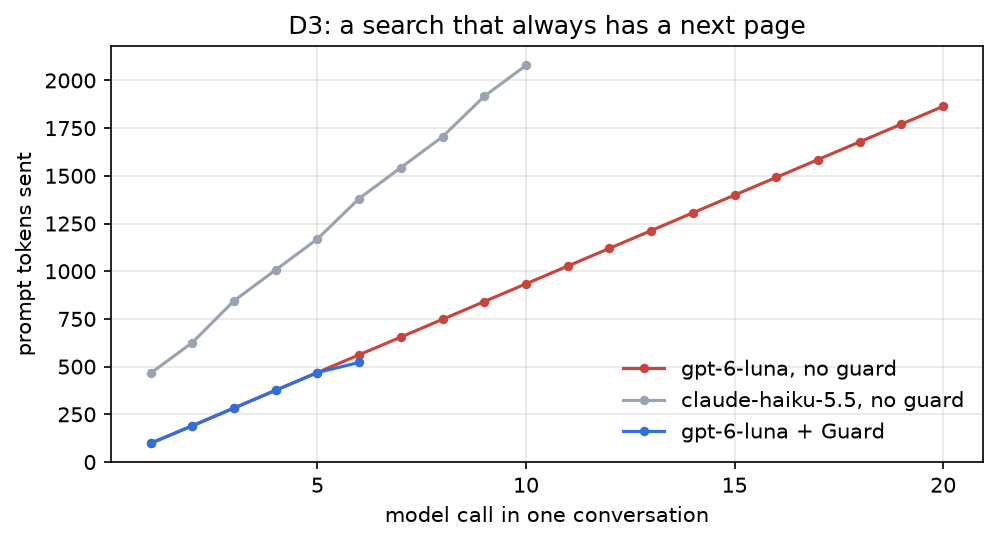

22-retry-storm.png


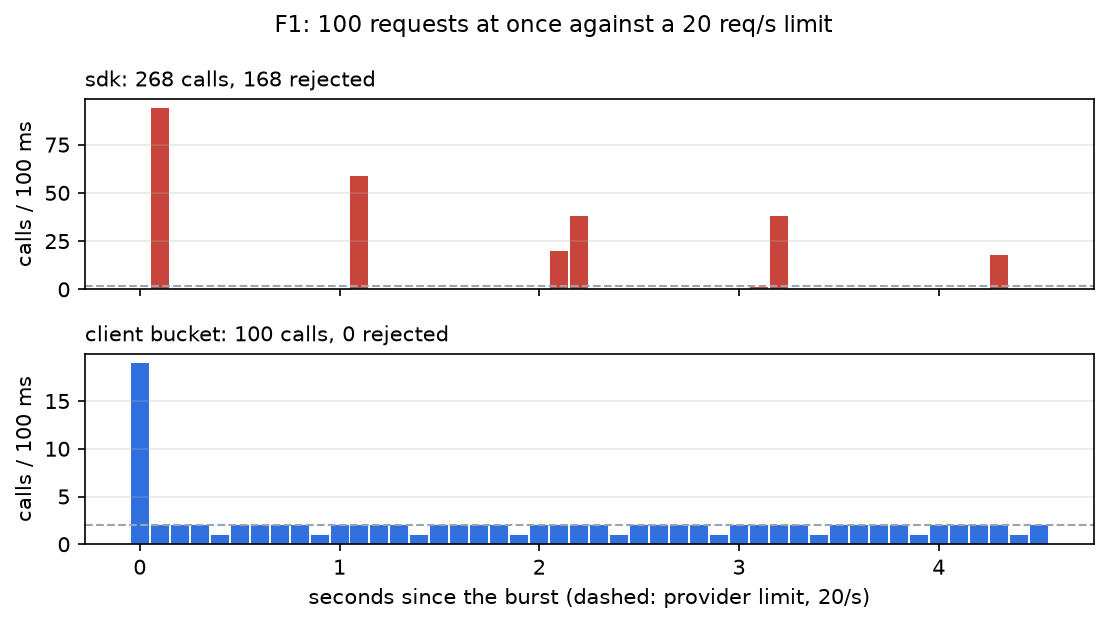

22-prompt-cache.png


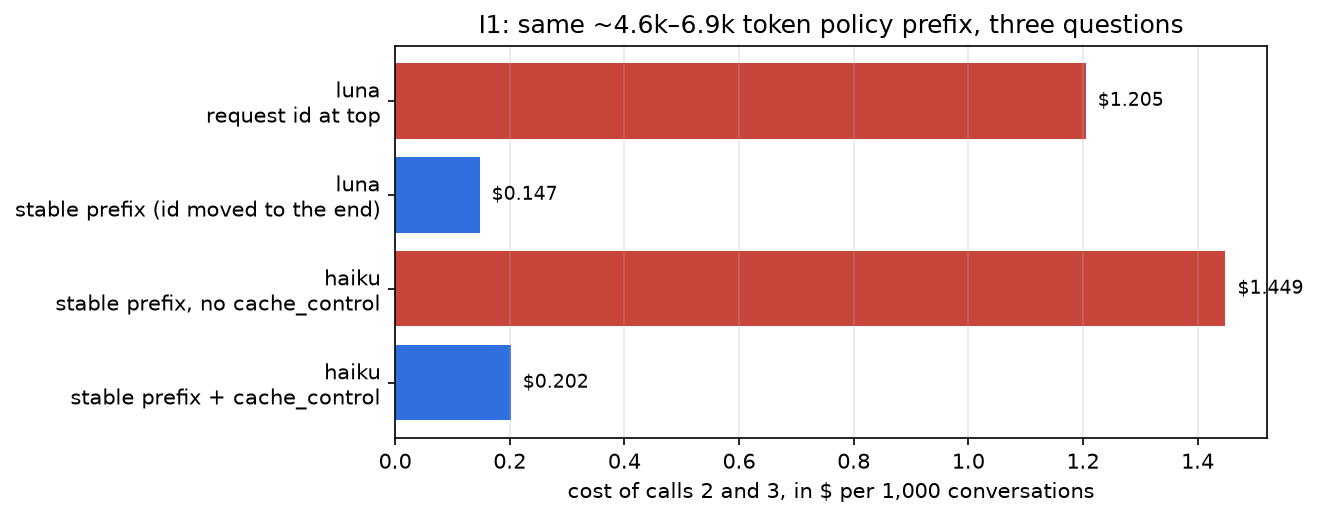

22-confidence.png


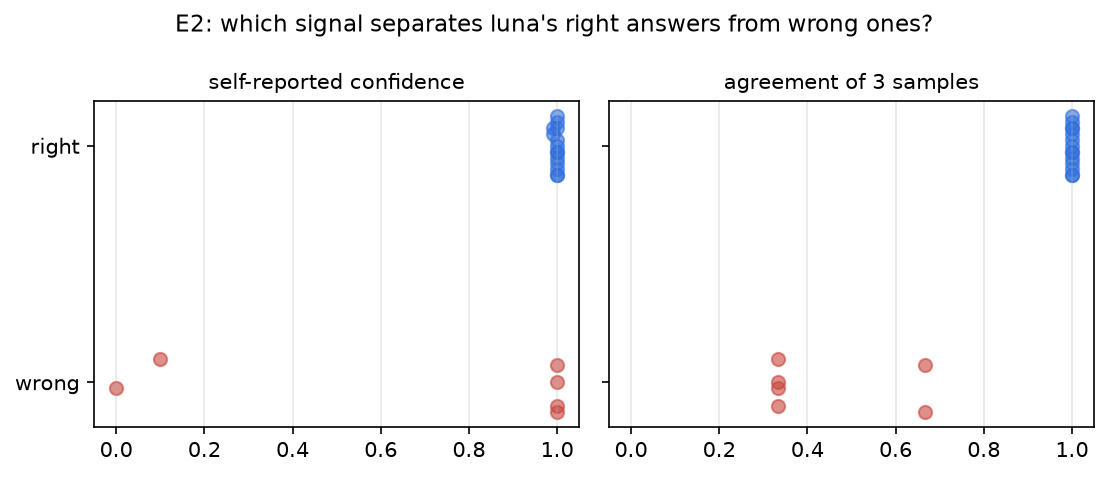

In [3]:
from IPython.display import Image, display

import ch22_charts as charts

data = json.loads(Path("results/run_all.json").read_text())
paths = [
    charts.overview(data),
    charts.agent_runaway(data["D3"]["data"]),
    charts.retry_storm(data["F1"]["data"]),
    charts.prompt_cache(data["I1"]["data"]),
    charts.confidence(data["E2"]["data"]),
]
for p in paths:
    print(p.name)
    display(Image(filename=str(p)))

## A few numbers behind the table

In [4]:
print("A5 o200k tokens per language:", data["A5"]["data"]["per_lang"])
print("A5 billed prompt tokens, same document:", data["A5"]["data"]["billed_prompt_tokens"])
print("A2 rows:")
for row in data["A2"]["data"]["rows"]:
    print("  ", row)
print("D3 prompt tokens per call, luna without guard:",
      [t["prompt_tokens"] for t in data["D3"]["data"]["luna"]["trace"]])
print("E3 gate block rates:", json.dumps(data["E3"]["data"], indent=1))
print("H2 attacker-link counts (naive/spotlight):", data["H2"]["data"])

A5 o200k tokens per language: {'English': {'chars': 79, 'tokens': 17}, 'Indonesian': {'chars': 82, 'tokens': 23}, 'Japanese': {'chars': 42, 'tokens': 29}, 'Emoji-heavy': {'chars': 79, 'tokens': 24}}
A5 billed prompt tokens, same document: {'openai/gpt-6-luna': 851, 'anthropic/claude-haiku-5.5': 1305}
A2 rows:
   {'model': 'qwen/qwen3.8-flash', 'reasoning_effort': 'default', 'finish_reason': 'stop', 'content_chars': 91, 'reasoning_tokens': 34, 'completion_tokens': 59, 'cost_usd': 4.243e-05}
   {'model': 'qwen/qwen3.8-flash', 'reasoning_effort': 'none', 'finish_reason': 'stop', 'content_chars': 113, 'reasoning_tokens': 0, 'completion_tokens': 24, 'cost_usd': 2.058e-05}
   {'model': 'openai/gpt-6-luna', 'reasoning_effort': 'default', 'finish_reason': 'stop', 'content_chars': 82, 'reasoning_tokens': 17, 'completion_tokens': 41, 'cost_usd': 2.46e-05}
   {'model': 'openai/gpt-6-luna', 'reasoning_effort': 'none', 'finish_reason': 'stop', 'content_chars': 84, 'reasoning_tokens': 0, 'completion

## Spend

In [5]:
from ch22_common import LEDGER

after = key_remaining()
print(f"this notebook's hosted calls: {LEDGER.calls}, usage.cost sum ${LEDGER.cost:.4f}")
print(f"key remaining ${before:.4f} -> ${after:.4f} (delta ${before - after:.4f}; the key is "
      "shared with other authors running at the same time, so the ledger is the exact number)")

this notebook's hosted calls: 409, usage.cost sum $0.0200
key remaining $14.6438 -> $14.6265 (delta $0.0174; the key is shared with other authors running at the same time, so the ledger is the exact number)
